## Individuell uppgift – Hälsostudie

### Del 1 – Grundläggande analys och statistik

#### Analys av hälsodata med beskrivande statistik, simulering, konfidensintervall och hypotesprövning.

In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

In [14]:
df = pd.read_csv("health_study_dataset.csv")
df.head()


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


## Översikt av datan

Datasetet innehåller 800 deltagare och 9 kolumner. Det finns inga saknade värden, så ingen datarensning behövs. Kolumnerna sex och smoker är kategoriska (text). Kolumnen disease lagras som siffror (0/1) men är också kategorisk: 1 betyder att personen har sjukdomen. Kolumnen id är bara ett löpnummer och används inte i analysen. Övriga kolumner är numeriska.

In [18]:
## Beskrivande analys för age, weight, height, systolic_bp, cholesterol

column = ["age","weight","height","systolic_bp","cholesterol"]
df[column].agg(["mean","median","min","max"]).round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


### Tolkning av beskrivande statistik

Medelvärde och median ligger mycket nära varandra för alla variabler, till exempel 149,2 och 149,4 mmHg för blodtryck. Det tyder på att fördelningarna är ungefär symmetriska utan stora extremvärden som drar medelvärdet åt ett håll.

Deltagarna är mellan 18 och 90 år, med en medelålder på cirka 49 år. Längd och vikt ligger inom rimliga intervall, men den lägsta vikten (33,7 kg) är ovanligt låg för en vuxen och kan vara ett extremvärde.

Medelvärdet för systoliskt blodtryck är cirka 149 mmHg, vilket är över den vanliga gränsen för högt blodtryck (cirka 140 mmHg). Deltagarna har alltså i genomsnitt förhöjt blodtryck. 

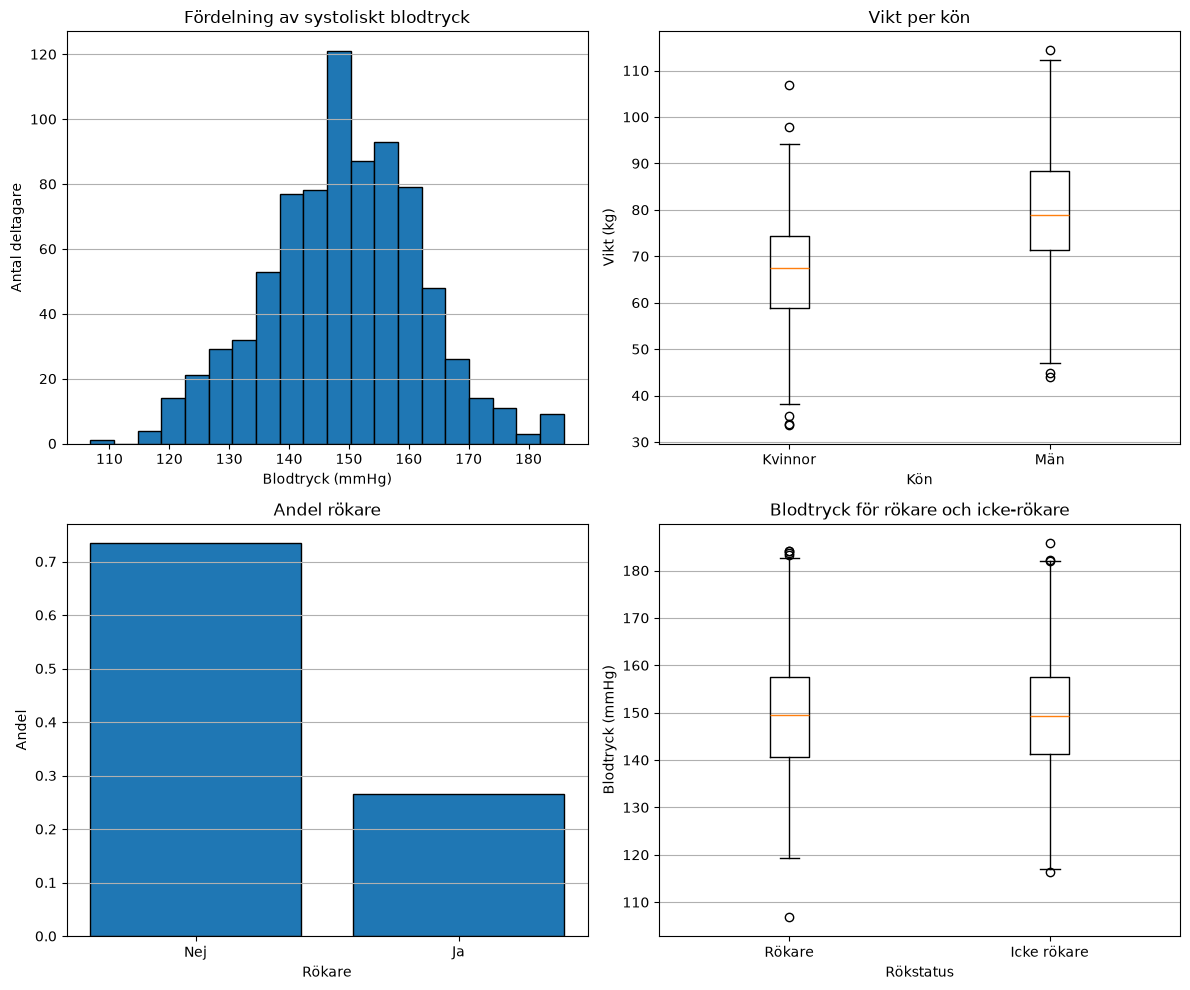

In [ ]:
## Visualisering

fig, axes = plt.subplots(2, 2, figsize = (12,10), sharex=False, sharey = False)

## Histogram över blodtryck

axes[0,0].hist(df["systolic_bp"], bins = 20, edgecolor = "black")
axes[0,0].set_title("Fördelning av systoliskt blodtryck")
axes[0,0].set_xlabel("Blodtryck (mmHg)")
axes[0,0].set_ylabel("Antal deltagare")
axes[0,0].grid(True, axis="y")

## Boxplot över vikt per kön

axes[0,1].boxplot([df.loc[df["sex"] == "F", "weight"], df.loc[df["sex"] == "M", "weight"]], tick_labels=["Kvinnor", "Män"])
axes[0,1].set_title("Vikt per kön")
axes[0,1].set_xlabel("Kön")
axes[0,1].set_ylabel("Vikt (kg)")
axes[0,1].grid(True, axis = "y")

## Stapeldiagram över andelen rökare

smoker_share = df["smoker"].value_counts(normalize=True).rename({"No":"Nej", "Yes":"Ja"})
axes[1, 0].bar(smoker_share.index, smoker_share.values, edgecolor="black")
axes[1, 0].set_title("Andel rökare")
axes[1, 0].set_xlabel("Rökare")
axes[1, 0].set_ylabel("Andel")
axes[1, 0].grid(True, axis="y")

## Boxplot över blodtryck för rökare och icke-rökare

axes[1,1].boxplot([df.loc[df["smoker"] == "Yes", "systolic_bp"], df.loc[df["smoker"] == "No","systolic_bp"]], tick_labels = ["Rökare","Icke-rökare"])
axes[1,1].set_title("Blodtryck för rökare och icke-rökare")
axes[1,1].set_xlabel("Rökstatus")
axes[1,1].set_ylabel("Blodtryck (mmHg)")              
axes[1,1].grid(True, axis = "y")

plt.tight_layout()
plt.show()


### Tolkning av graferna

**Histogram:** Blodtrycket är ungefär normalfördelat, med de flesta deltagarna kring 145–155 mmHg. Det stämmer med att medelvärde och median ligger nära varandra.

**Vikt per kön:** Män väger i genomsnitt mer än kvinnor (median cirka 79 kg mot 67 kg). Båda grupperna har några extremvärden, bland annat den låga vikten på 33,7 kg.

**Andel rökare:** Cirka 27 % av deltagarna röker och 73 % röker inte. Grupperna är alltså olika stora.

**Blodtryck för rökare och icke-rökare:** Boxplottarna är nästan identiska, med median kring 149–150 mmHg i båda grupperna. Det finns ingen tydlig skillnad i grafen, men det undersöks närmare med en hypotesprövning senare.